# Phase 9.1 - Mejora Gated + Comparación con Phase 9

Mejora aplicada:
- Cabeza binaria `informativo vs ruido`.
- Cabeza de subclase solo para informativos.
- Cabeza de regresión de completitud.
- Umbral calibrado en validación.

Este notebook ejecuta `phase9.1` y compara contra `phase9`.

In [1]:
from pathlib import Path
import json
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

ROOT = Path('.')
PHASE9 = ROOT / 'phases/phase09_multitask_patterns'

RUN_V91 = PHASE9 / 'run_phase9_1_multitask_gated.py'
SUM_V9 = PHASE9 / 'output_phase9_partial_pattern_GBPUSD/GBPUSD_phase9_summary.json'
SUM_V91 = PHASE9 / 'output_phase9_1_partial_pattern_GBPUSD/GBPUSD_phase9_1_summary.json'
PRED_V9 = PHASE9 / 'output_phase9_partial_pattern_GBPUSD/GBPUSD_phase9_test_predictions.csv'
PRED_V91 = PHASE9 / 'output_phase9_1_partial_pattern_GBPUSD/GBPUSD_phase9_1_test_predictions.csv'
SCAN_V91 = PHASE9 / 'output_phase9_1_partial_pattern_GBPUSD/GBPUSD_phase9_1_val_threshold_scan.csv'

In [2]:
subprocess.run(['python', str(RUN_V91)], check=True)
print('Ejecutado:', RUN_V91)

Saved summary: ./phases/phase09_multitask_patterns/output_phase9_1_partial_pattern_GBPUSD/GBPUSD_phase9_1_summary.json
Test metrics: {'acc': 0.6531881804043546, 'f1_macro_all': 0.5056118150121358, 'f1_macro_informative': 0.5639692862346392, 'recall_class0': 0.7326493663246831, 'mae_progress': 0.06401263922452927, 'rmse_progress': 0.09165177494287491, 'mae_progress_early': 0.07076187431812286, 'n_informative': 1187}


Ejecutado: ./phases/phase09_multitask_patterns/run_phase9_1_multitask_gated.py


In [3]:
s9 = json.loads(SUM_V9.read_text())
s91 = json.loads(SUM_V91.read_text())

metrics = [
    'acc',
    'f1_macro_all',
    'f1_macro_informative',
    'mae_progress',
    'mae_progress_early',
]

rows = []
for m in metrics:
    rows.append({
        'metric': m,
        'phase9': float(s9['test_metrics'].get(m, np.nan)),
        'phase9_1': float(s91['test_metrics'].get(m, np.nan)),
        'delta_v91_minus_v9': float(s91['test_metrics'].get(m, np.nan) - s9['test_metrics'].get(m, np.nan)),
    })

# recall_class0 exists only in v9.1 summary
df_cmp = pd.DataFrame(rows)
df_cmp.round(4)

,metric,phase9,phase9_1,delta_v91_minus_v9
0,acc,0.3875,0.6532,0.2657
1,f1_macro_all,0.3922,0.5056,0.1134
2,f1_macro_informative,0.7622,0.5640,-0.1982
3,mae_progress,0.0622,0.0640,0.0018
4,mae_progress_early,0.0617,0.0708,0.0090


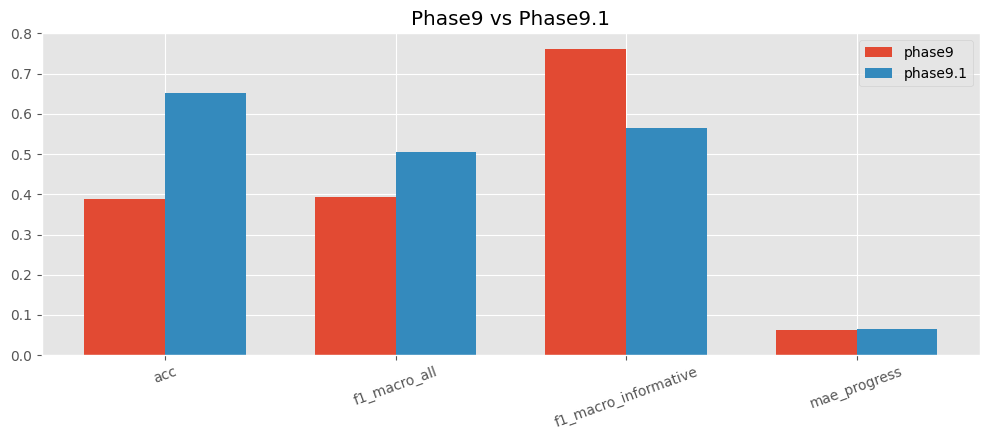

In [4]:
plt.style.use('ggplot')
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_df = df_cmp.copy()
plot_df = plot_df[plot_df['metric'].isin(['acc','f1_macro_all','f1_macro_informative','mae_progress'])]

x = np.arange(len(plot_df))
w = 0.35
ax.bar(x - w/2, plot_df['phase9'], width=w, label='phase9')
ax.bar(x + w/2, plot_df['phase9_1'], width=w, label='phase9.1')
ax.set_xticks(x)
ax.set_xticklabels(plot_df['metric'], rotation=20)
ax.set_title('Phase9 vs Phase9.1')
ax.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_3564118/3433179089.py:27: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


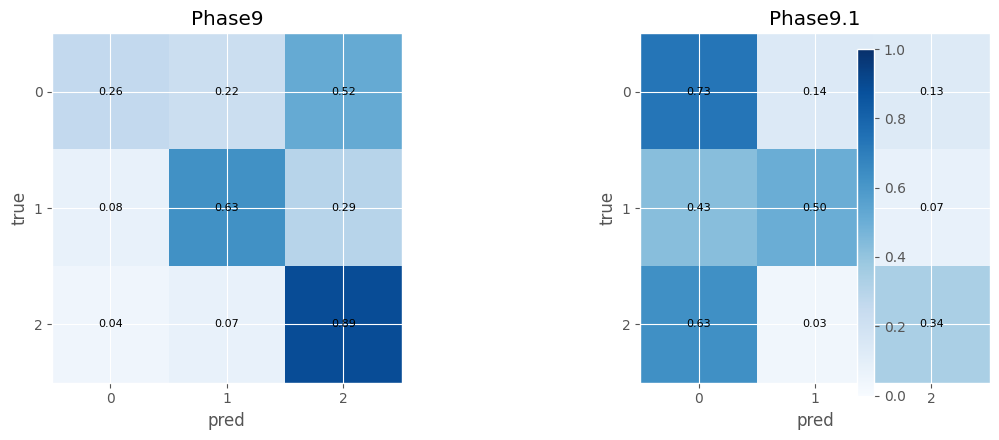

In [5]:
pred9 = pd.read_csv(PRED_V9)
pred91 = pd.read_csv(PRED_V91)

labels = sorted(set(pred9['y_class'].unique().tolist()) | set(pred9['pred_class'].unique().tolist()) | set(pred91['pred_class'].unique().tolist()))

cm9 = confusion_matrix(pred9['y_class'], pred9['pred_class'], labels=labels)
cm91 = confusion_matrix(pred91['y_class'], pred91['pred_class'], labels=labels)

cm9n = cm9 / np.clip(cm9.sum(axis=1, keepdims=True), 1, None)
cm91n = cm91 / np.clip(cm91.sum(axis=1, keepdims=True), 1, None)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, cmn, title in zip(axes, [cm9n, cm91n], ['Phase9', 'Phase9.1']):
    im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xlabel('pred')
    ax.set_ylabel('true')
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels)
    ax.set_yticklabels(labels)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{cmn[i,j]:.2f}", ha='center', va='center', fontsize=8)

fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.03, pad=0.02)
plt.tight_layout()
plt.show()

In [6]:
scan = pd.read_csv(SCAN_V91)
scan.sort_values('score', ascending=False).head(10)

,thr,score,acc,f1_macro_all,f1_macro_informative,recall_class0,mae_progress,rmse_progress,mae_progress_early,n_informative
12,0.500,0.718162,0.644514,0.502858,0.570307,0.727273,0.083325,0.133624,0.099922,1195
13,0.525,0.699204,0.698707,0.497526,0.471657,0.837641,0.083325,0.133624,0.099922,1195
11,0.475,0.673489,0.519179,0.455912,0.669394,0.502280,0.083325,0.133624,0.099922,1195
14,0.550,0.667318,0.711864,0.477152,0.412112,0.871389,0.083325,0.133624,0.099922,1195
10,0.450,0.644231,0.457627,0.426853,0.713232,0.390696,0.083325,0.133624,0.099922,1195
15,0.575,0.635841,0.722569,0.455798,0.360791,0.898449,0.083325,0.133624,0.099922,1195
9,0.425,0.631683,0.433764,0.413593,0.733837,0.346306,0.083325,0.133624,0.099922,1195
8,0.400,0.617590,0.409456,0.399184,0.752861,0.301915,0.083325,0.133624,0.099922,1195
16,0.600,0.612261,0.723684,0.439512,0.327724,0.908179,0.083325,0.133624,0.099922,1195
7,0.375,0.599953,0.383586,0.381817,0.769896,0.256613,0.083325,0.133624,0.099922,1195


## Lectura rápida

- `phase9.1` prioriza separar bien ruido (`class 0`) sin perder multitarea.
- Revisa el tradeoff entre `f1_macro_all` y `f1_macro_informative` para elegir umbral según tu objetivo.
- Si quieres modo más "agresivo" para informativos, baja el umbral (`thr`) desde la tabla de scan.
